Дано:
- гиперпараметр числа соседей (n_neighbors)

Требуется:
- дописать класс kNN;
- проверить работу алгоритма на тестовой выборке и посчитать достоверность (accuracy) модели;
- нирисовать график зависимости достоверности на тестовой выборке от числа соседей k.

Создание данных (make_moons - перекрывающиеся кластеры)
Распределение классов: [150 150]
Обучающая: 180, Тестовая: 120
Распределение в train: [98 82]
Распределение в test: [52 68]


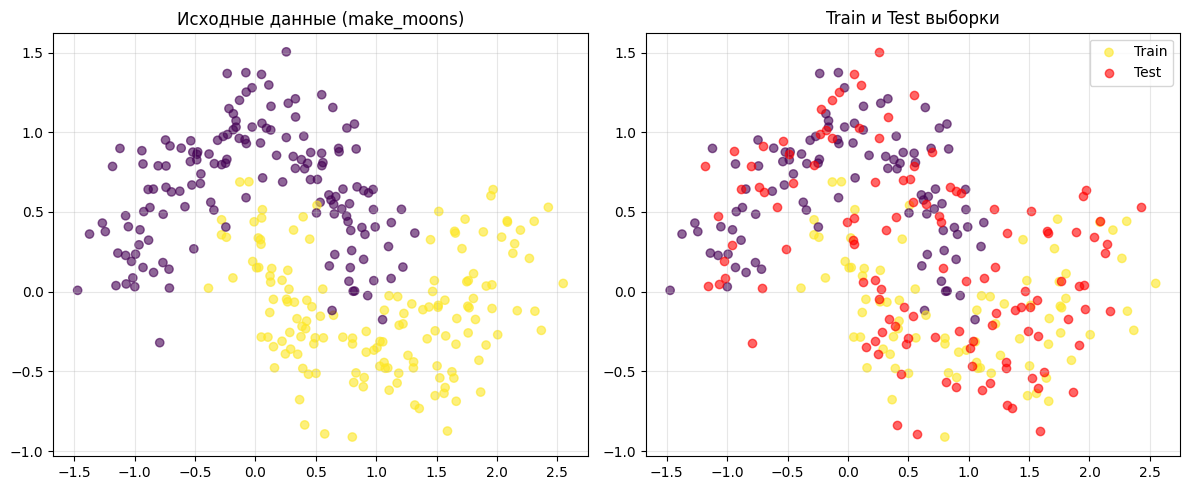


Зависимость accuracy от k

k     Accuracy        Правильно       Всего     
--------------------------------------------------
1     0.9583          115             120       
2     0.9583          115             120       
3     0.9833          118             120       
4     0.9667          116             120       
5     0.9667          116             120       
6     0.9667          116             120       
7     0.9667          116             120       
8     0.9833          118             120       
9     0.9750          117             120       
10    0.9833          118             120       
11    0.9833          118             120       
12    0.9833          118             120       
13    0.9833          118             120       
14    0.9917          119             120       
15    0.9833          118             120       
16    0.9917          119             120       
17    0.9833          118             120       
18    0.9917          119             1

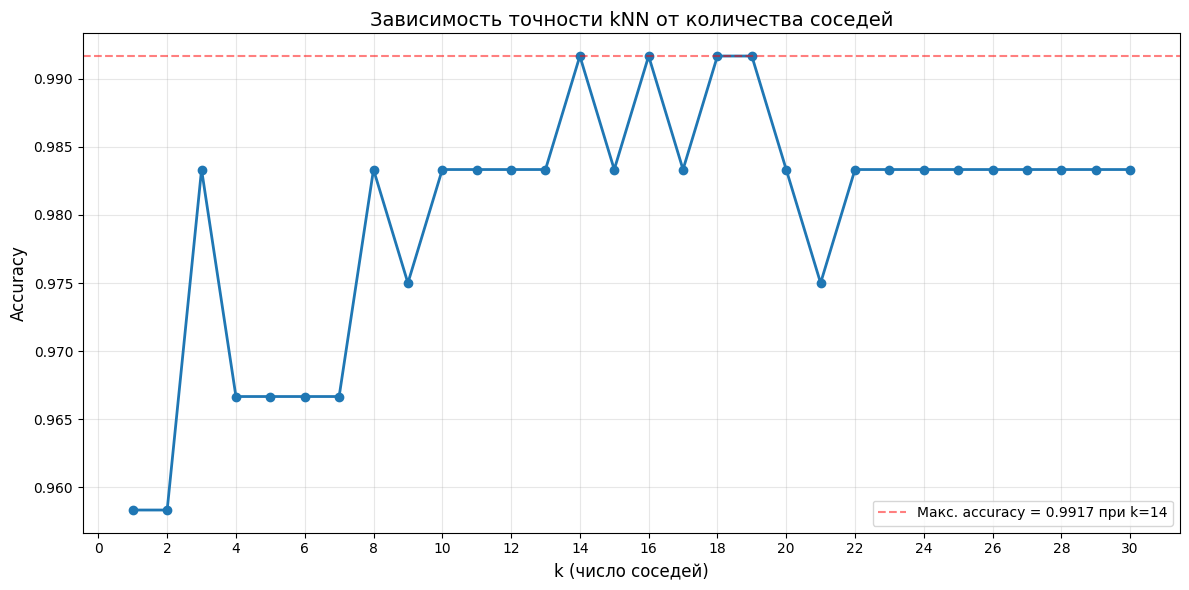


Оптимальное k: 14
Максимальная точность: 0.9917

Финальная модель с оптимальным k
Точность: 0.9917


/tmp/ipykernel_1995/70666560.py:155: UserWarning: You passed a edgecolor/edgecolors ('w') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',


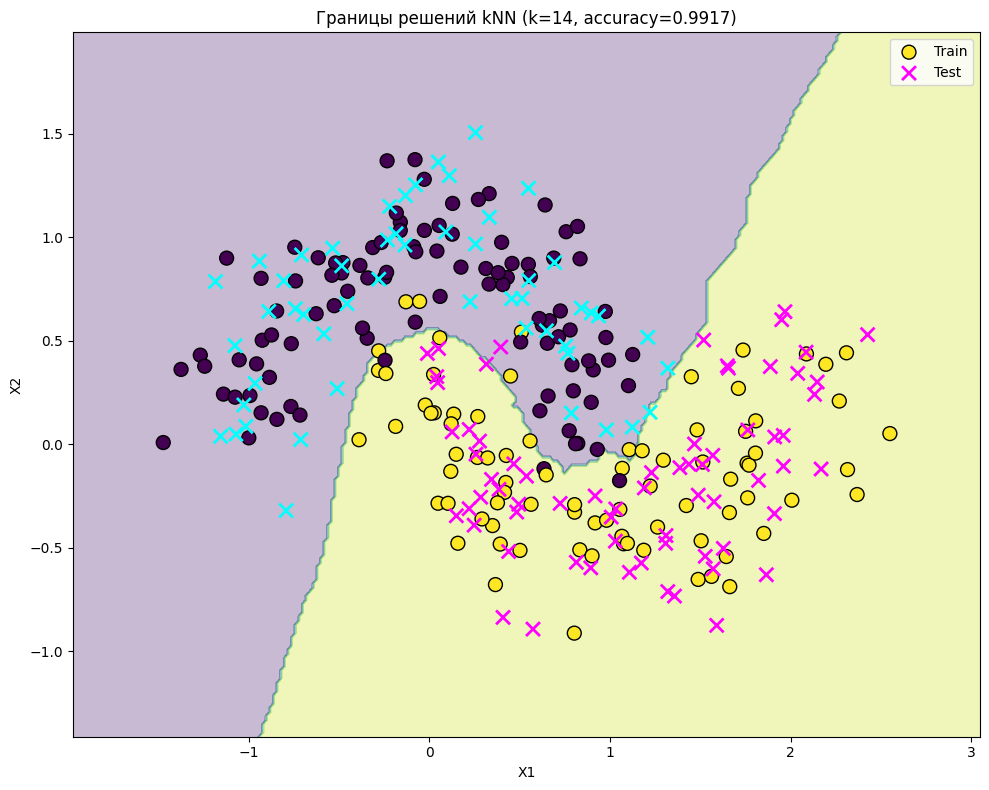

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

class kNN():

    def __init__(self, dataset, targets, n_neighbors=3):
        self.dataset = np.array(dataset)
        self.targets = np.array(targets)
        self.n_neighbors = n_neighbors
        self.fitted = False

    def get_dist(self, list1, list2):
        return np.sqrt(sum((i - j) ** 2 for i, j in zip(list1, list2)))

    def fit(self):
        self.fitted = True
        return self

    def predict(self, list2d):
        if not self.fitted:
            raise ValueError("Модель еще не обучена. Вызовите fit() перед predict().")

        list2d = np.array(list2d)
        predictions = []

        for point in list2d:
            distances = np.array([self.get_dist(point, train_point)
                                 for train_point in self.dataset])

            k_nearest_indices = np.argsort(distances)[:self.n_neighbors]
            k_nearest_labels = self.targets[k_nearest_indices]

            unique, counts = np.unique(k_nearest_labels, return_counts=True)
            predicted_label = unique[np.argmax(counts)]
            predictions.append(predicted_label)

        return np.array(predictions)

print("=" * 60)
print("Создание данных")
print("=" * 60)

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

print(f"Распределение классов: {np.bincount(y)}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Обучающая: {X_train.shape[0]}, Тестовая: {X_test.shape[0]}")
print(f"Распределение в train: {np.bincount(y_train)}")
print(f"Распределение в test: {np.bincount(y_test)}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', alpha=0.6)
plt.title('Исходные данные (make_moons)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', alpha=0.6, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c='red', alpha=0.6, label='Test')
plt.legend()
plt.title('Train и Test выборки')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Зависимость accuracy от k")
print("=" * 60)

k_values = list(range(1, 31))
accuracies = []

print(f"\n{'k':<5} {'Accuracy':<15} {'Правильно':<15} {'Всего':<10}")
print("-" * 50)

for k in k_values:
    knn_test = kNN(X_train, y_train, n_neighbors=k)
    knn_test.fit()

    y_pred_test = knn_test.predict(X_test)
    acc = accuracy_score(y_test, y_pred_test)
    accuracies.append(acc)

    correct = (y_test == y_pred_test).sum()
    print(f"{k:<5} {acc:<15.4f} {correct:<15} {len(y_test):<10}")

plt.figure(figsize=(12, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='-', linewidth=2, markersize=6)
plt.xlabel('k (число соседей)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Зависимость точности kNN от количества соседей', fontsize=14)
plt.grid(True, alpha=0.3)
plt.xticks(range(0, 31, 2))
plt.axhline(y=max(accuracies), color='r', linestyle='--', alpha=0.5,
            label=f'Макс. accuracy = {max(accuracies):.4f} при k={k_values[np.argmax(accuracies)]}')
plt.legend()
plt.tight_layout()
plt.show()

optimal_k = k_values[np.argmax(accuracies)]
print(f"\nОптимальное k: {optimal_k}")
print(f"Максимальная точность: {max(accuracies):.4f}")

print("\n" + "=" * 60)
print("Финальная модель с оптимальным k")
print("=" * 60)

final_model = kNN(X_train, y_train, n_neighbors=optimal_k)
final_model.fit()

y_pred_final = final_model.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred_final)

print(f"Точность: {final_accuracy:.4f}")

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

Z = final_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis',
            edgecolors='k', s=100, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',
            edgecolors='w', s=100, marker='x', linewidths=2, label='Test')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title(f'Границы решений kNN (k={optimal_k}, accuracy={final_accuracy:.4f})')
plt.legend()
plt.tight_layout()
plt.show()


Дано:
- гиперпараметр число эпох обучения (epochs);
- гиперпараметр скорость обучения (eta).

Требуется:
- дописать класс LogReg;
- для метода predict() можно использовать, например, метод np.rint() округления значения логистической функции до ближайшего целого;
- проверить работу алгоритма на тестовой выборке и посчитать достоверность (accuracy) модели.

Создание данных
Размер данных: (300, 2)


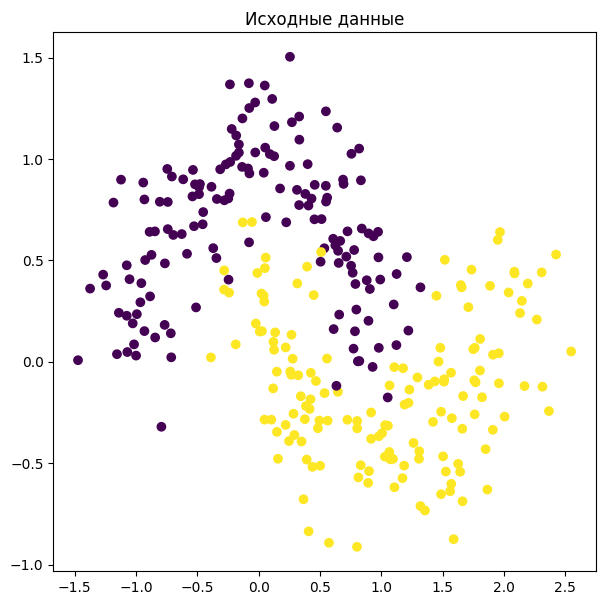


Разбиение на обучающую и тестовую выборки
Обучающая выборка: 180 образцов
Тестовая выборка: 120 образцов


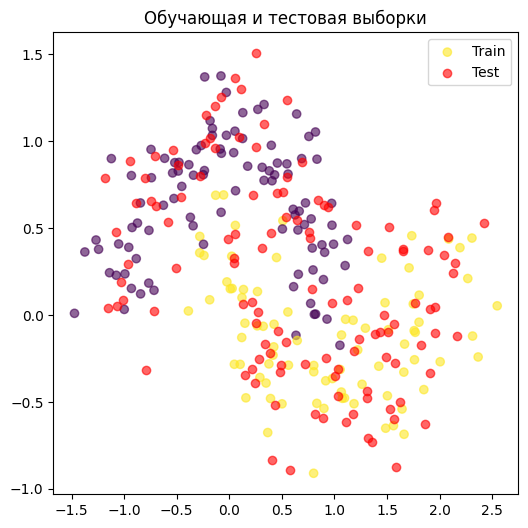


Обучение модели LogReg
Эпоха   0: MSE = 0.291474
Эпоха  10: MSE = 0.243811
Эпоха  20: MSE = 0.209218
Эпоха  30: MSE = 0.185475
Эпоха  40: MSE = 0.169280
Эпоха  50: MSE = 0.157983
Эпоха  60: MSE = 0.149827
Эпоха  70: MSE = 0.143720
Эпоха  80: MSE = 0.138989
Эпоха  90: MSE = 0.135212

Обучение завершено. Финальная MSE: 0.132404

Предсказание и оценка качества

Точность (accuracy) модели: 0.8667

Первые 10 истинных меток: [1 1 1 1 1 0 1 0 1 1]
Первые 10 предсказаний:    [1 1 1 1 1 0 1 0 1 1]

Сходимость модели


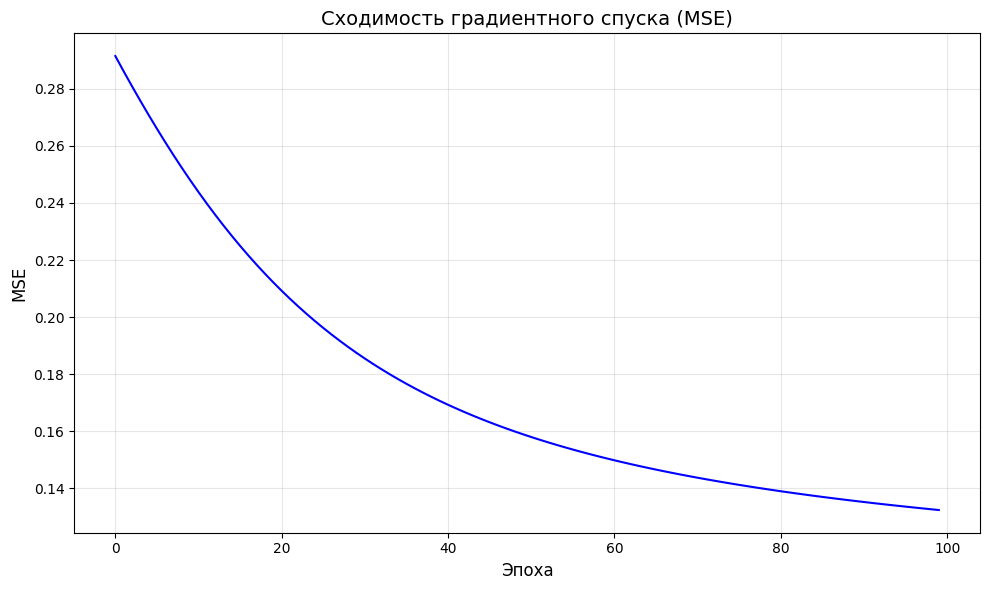


Границы решений


/tmp/ipykernel_2632/919174856.py:137: UserWarning: You passed a edgecolor/edgecolors ('w') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',


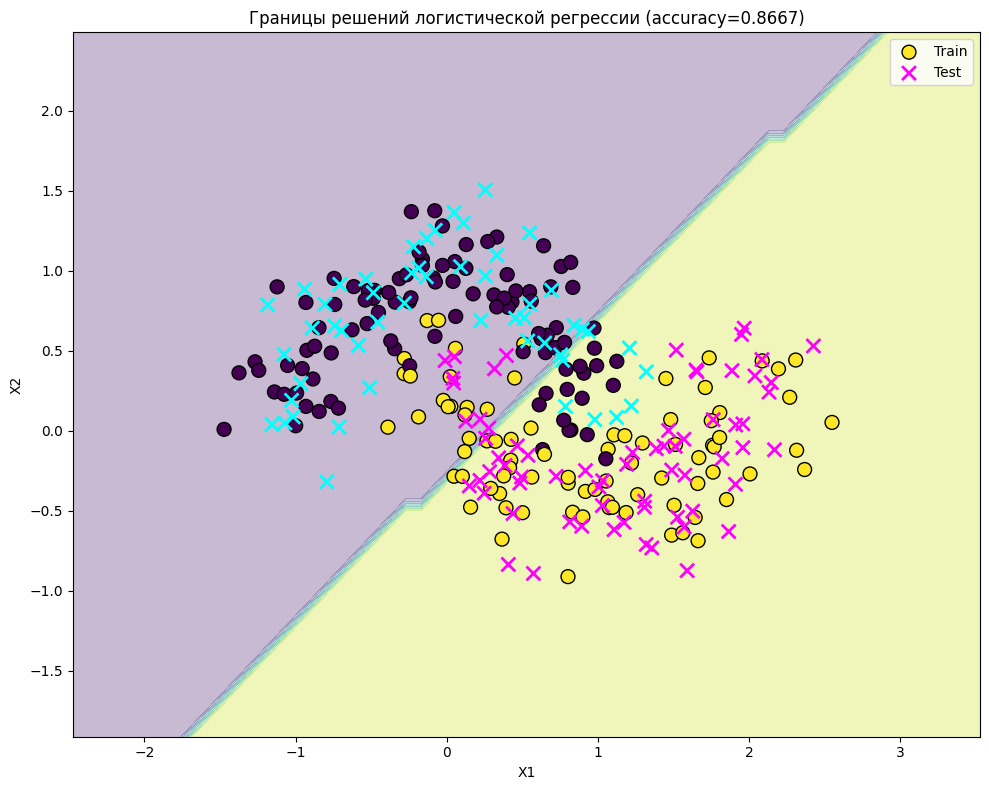


Тестирование predict() с новыми данными

Предсказания для новых точек:
Точка                          Предсказание   
---------------------------------------------
  [-1.47250233 -0.91160797] -> 0
  [0.5381309  0.29635004] -> 0
  [2.54876413 1.50430805] -> 1

Веса модели

Веса (включая bias):
  w1 = 1.0400
  w2 = -1.0851
  bias = -0.2703


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

class LogReg():

    def __init__(self, dataset, targets, epochs=100, eta=0.1):
        self.dataset = np.array(dataset)
        self.targets = np.array(targets).reshape(-1, 1)
        self.epochs = epochs
        self.eta = eta

        n_samples = self.dataset.shape[0]
        self.X = np.hstack([self.dataset, np.ones((n_samples, 1))])

        self.W = np.random.random((self.X.shape[1], 1))

        self.loss_history = []

    def sigmoid(self, x, deriv=False):
        if deriv:
            s = 1 / (1 + np.exp(-x))
            return s * (1 - s)
        return 1 / (1 + np.exp(-x))

    def fit(self):
        n_samples = self.X.shape[0]

        for epoch in range(self.epochs):
            y_pred = self.sigmoid(np.dot(self.X, self.W))

            error = self.targets - y_pred

            gradient = -np.dot(self.X.T, error) / n_samples

            self.W -= self.eta * gradient

            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

            if epoch % 10 == 0:
                print(f"Эпоха {epoch:3d}: MSE = {mse:.6f}")

        print(f"\nОбучение завершено. Финальная MSE: {mse:.6f}")
        return self

    def predict(self, list2d):
        list2d = np.array(list2d)

        n_samples = list2d.shape[0]
        X_test = np.hstack([list2d, np.ones((n_samples, 1))])

        y_pred_prob = self.sigmoid(np.dot(X_test, self.W))

        y_pred = np.rint(y_pred_prob).astype('int')

        return y_pred.flatten()

print("=" * 60)
print("Создание данных")
print("=" * 60)

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

print(f"Размер данных: {X.shape}")

plt.figure(figsize=(7, 7))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis')
plt.title('Исходные данные')
plt.show()

print("\n" + "=" * 60)
print("Разбиение на обучающую и тестовую выборки")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} образцов")
print(f"Тестовая выборка: {X_test.shape[0]} образцов")

plt.figure(figsize=(6, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', alpha=0.6, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c='red', alpha=0.6, label='Test')
plt.legend()
plt.title('Обучающая и тестовая выборки')
plt.show()

print("\n" + "=" * 60)
print("Обучение модели LogReg")
print("=" * 60)

logreg = LogReg(X_train, y_train, epochs=100, eta=0.1)
logreg.fit()

print("\n" + "=" * 60)
print("Предсказание и оценка качества")
print("=" * 60)

y_pred = logreg.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nТочность (accuracy) модели: {accuracy:.4f}")

print(f"\nПервые 10 истинных меток: {y_test[:10]}")
print(f"Первые 10 предсказаний:    {y_pred[:10]}")

print("\n" + "=" * 60)
print("Сходимость модели")
print("=" * 60)

plt.figure(figsize=(10, 6))
plt.plot(logreg.loss_history, color='blue')
plt.xlabel('Эпоха', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.title('Сходимость градиентного спуска (MSE)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Границы решений")
print("=" * 60)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

Z = logreg.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis',
            edgecolors='k', s=100, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',
            edgecolors='w', s=100, marker='x', linewidths=2, label='Test')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title(f'Границы решений логистической регрессии (accuracy={accuracy:.4f})')
plt.legend()
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Тестирование predict() с новыми данными")
print("=" * 60)

test_points = np.array([
    [X[:, 0].min(), X[:, 1].min()],
    [(X[:, 0].min() + X[:, 0].max()) / 2, (X[:, 1].min() + X[:, 1].max()) / 2],
    [X[:, 0].max(), X[:, 1].max()]
])

predictions = logreg.predict(test_points)

print(f"\nПредсказания для новых точек:")
print(f"{'Точка':<30} {'Предсказание':<15}")
print("-" * 45)
for i, (point, pred) in enumerate(zip(test_points, predictions)):
    print(f"  {point} -> {pred}")

print("\n" + "=" * 60)
print("Веса модели")
print("=" * 60)

print(f"\nВеса (включая bias):")
for i, w in enumerate(logreg.W.flatten()):
    if i < len(logreg.W) - 1:
        print(f"  w{i+1} = {w:.4f}")
    else:
        print(f"  bias = {w:.4f}")


Дано:
- гиперпараметр скорость обучения (eta);
- гиперпараметр регуляризации весов (lambda_param);
- гиперпараметр число эпох обучения (epochs).

Требуется:
- дописать метод predict();
- проверить работу алгоритма на тестовой выборке и посчитать достоверность (accuracy) модели.

Создание данных
Размер данных: (300, 2)
Распределение классов: [150 150]


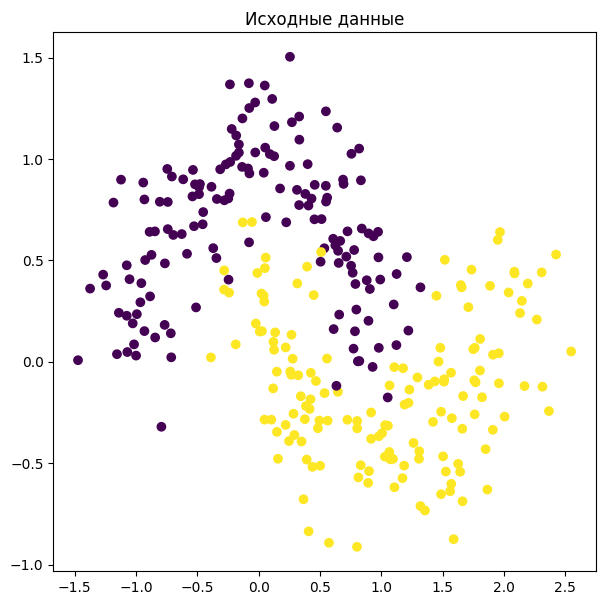


Разбиение на обучающую и тестовую выборки
Обучающая выборка: 180 образцов
Тестовая выборка: 120 образцов


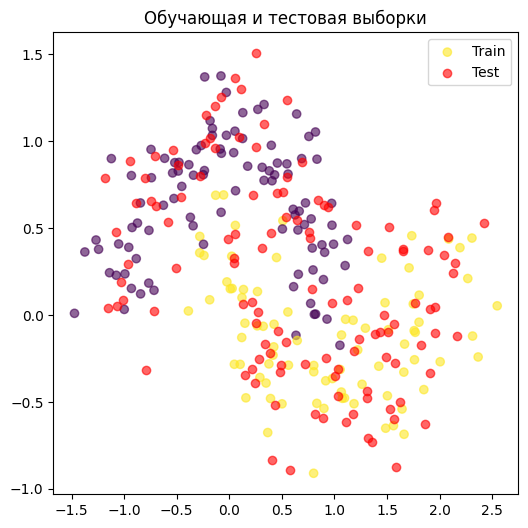


Обучение модели SVM
Модель обучена за 1000 эпох
Веса W: [ 0.69626217 -1.84097161]
Смещение w0: -0.1700

Предсказание и оценка качества

Точность (accuracy) модели: 0.8917

Первые 10 истинных меток: [1 1 1 1 1 0 1 0 1 1]
Первые 10 предсказаний:    [1 1 1 1 1 0 1 0 1 1]

Границы решений


/tmp/ipykernel_2632/725573499.py:119: UserWarning: You passed a edgecolor/edgecolors ('w') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',


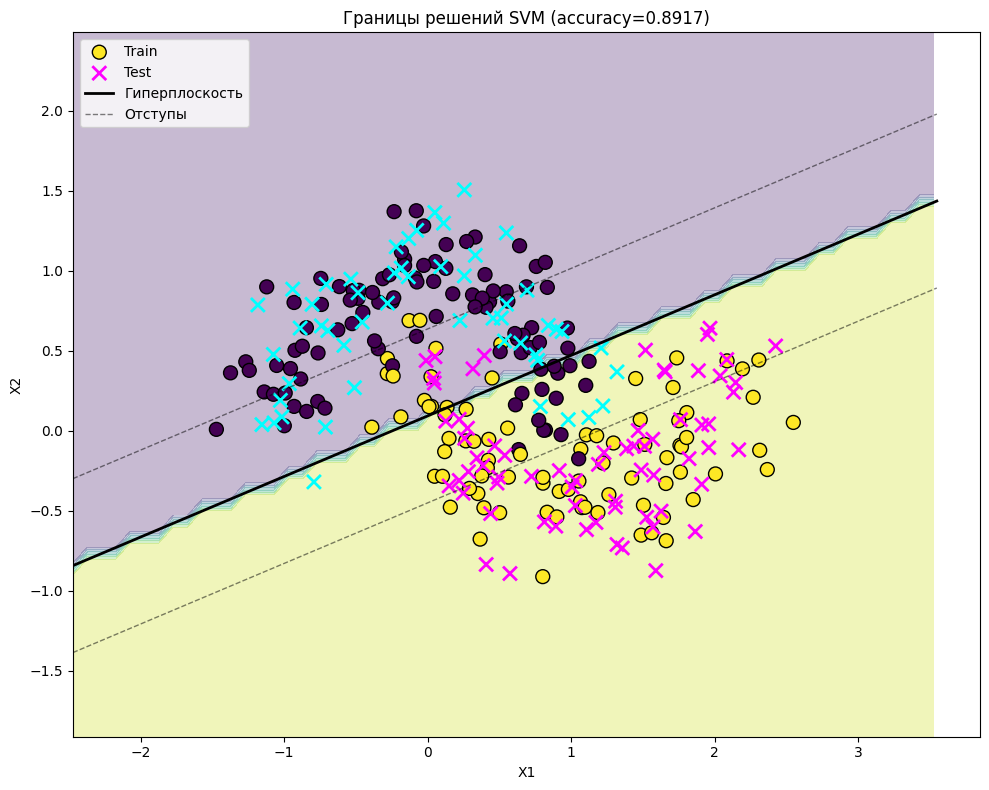


Тестирование predict() с новыми данными

Предсказания для новых точек:
Точка                          Предсказание   
---------------------------------------------
  [-1.47250233 -0.91160797] -> 1
  [0.5381309  0.29635004] -> 0
  [2.54876413 1.50430805] -> 0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

class SVM:
    def __init__(self, dataset, targets, eta=0.001, lambda_param=0.01, epochs=1000):

        self.dataset = np.array(dataset)
        self.targets = np.array(targets)
        self.lr = eta
        self.lambda_param = lambda_param
        self.epochs = epochs
        self.W = None
        self.w0 = None
        self.fitted = False

    def fit(self):
        n_samples, n_features = self.dataset.shape

        y_ = np.where(self.targets <= 0, -1, 1)

        self.W = np.zeros(n_features)
        self.w0 = 0

        for epoch in range(self.epochs):
            for idx, x_i in enumerate(self.dataset):
                condition = y_[idx] * (np.dot(x_i, self.W) - self.w0) >= 1

                if condition:
                    self.W -= self.lr * (2 * self.lambda_param * self.W)
                else:
                    self.W -= self.lr * (2 * self.lambda_param * self.W - np.dot(x_i, y_[idx]))
                    self.w0 -= self.lr * y_[idx]

        self.fitted = True
        print(f"Модель обучена за {self.epochs} эпох")
        print(f"Веса W: {self.W}")
        print(f"Смещение w0: {self.w0:.4f}")
        return self

    def predict(self, list2d):
        if not self.fitted:
            raise ValueError("Модель еще не обучена. Вызовите fit() перед predict().")

        list2d = np.array(list2d)

        predictions = np.dot(list2d, self.W) - self.w0

        predicted_labels = np.where(predictions > 0, 1, 0)

        return predicted_labels

print("=" * 60)
print("Создание данных")
print("=" * 60)

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

print(f"Размер данных: {X.shape}")
print(f"Распределение классов: {np.bincount(y)}")

plt.figure(figsize=(7, 7))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis')
plt.title('Исходные данные')
plt.show()

print("\n" + "=" * 60)
print("Разбиение на обучающую и тестовую выборки")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} образцов")
print(f"Тестовая выборка: {X_test.shape[0]} образцов")

plt.figure(figsize=(6, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', alpha=0.6, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c='red', alpha=0.6, label='Test')
plt.legend()
plt.title('Обучающая и тестовая выборки')
plt.show()

print("\n" + "=" * 60)
print("Обучение модели SVM")
print("=" * 60)

svm_model = SVM(X_train, y_train, eta=0.01, lambda_param=0.01, epochs=1000)
svm_model.fit()

print("\n" + "=" * 60)
print("Предсказание и оценка качества")
print("=" * 60)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nТочность (accuracy) модели: {accuracy:.4f}")

print(f"\nПервые 10 истинных меток: {y_test[:10]}")
print(f"Первые 10 предсказаний:    {y_pred[:10]}")

print("\n" + "=" * 60)
print("Границы решений")
print("=" * 60)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis',
            edgecolors='k', s=100, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',
            edgecolors='w', s=100, marker='x', linewidths=2, label='Test')


if np.abs(svm_model.W[1]) > 1e-6:
    x_line = np.array([x_min, x_max])
    w0, w1, w2 = svm_model.w0, svm_model.W[0], svm_model.W[1]

    y_line = (w0 - w1 * x_line) / w2
    plt.plot(x_line, y_line, 'k-', linewidth=2, label='Гиперплоскость')

    y_margin1 = (w0 - w1 * x_line + 1) / w2
    y_margin2 = (w0 - w1 * x_line - 1) / w2
    plt.plot(x_line, y_margin1, 'k--', linewidth=1, alpha=0.5, label='Отступы')
    plt.plot(x_line, y_margin2, 'k--', linewidth=1, alpha=0.5)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title(f'Границы решений SVM (accuracy={accuracy:.4f})')
plt.legend()
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Тестирование predict() с новыми данными")
print("=" * 60)

test_points = np.array([
    [X[:, 0].min(), X[:, 1].min()],
    [(X[:, 0].min() + X[:, 0].max()) / 2, (X[:, 1].min() + X[:, 1].max()) / 2],
    [X[:, 0].max(), X[:, 1].max()]
])

predictions = svm_model.predict(test_points)

print(f"\nПредсказания для новых точек:")
print(f"{'Точка':<30} {'Предсказание':<15}")
print("-" * 45)
for i, (point, pred) in enumerate(zip(test_points, predictions)):
    print(f"  {point} -> {pred}")


Требуется:
- написать метод наивного байесовского классификатора для упорядоченных признаков с непрерывным респределением. Использовать условную вероятность для гауссовского классификатора.

Создание данных (gaussian blobs)
Размер данных: (300, 2)
Распределение классов: [150 150]


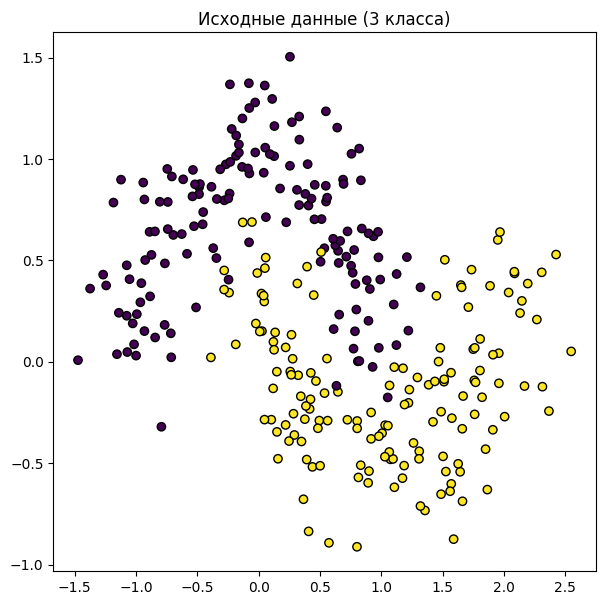


Разбиение на обучающую и тестовую выборки
Обучающая выборка: 180 образцов
Тестовая выборка: 120 образцов


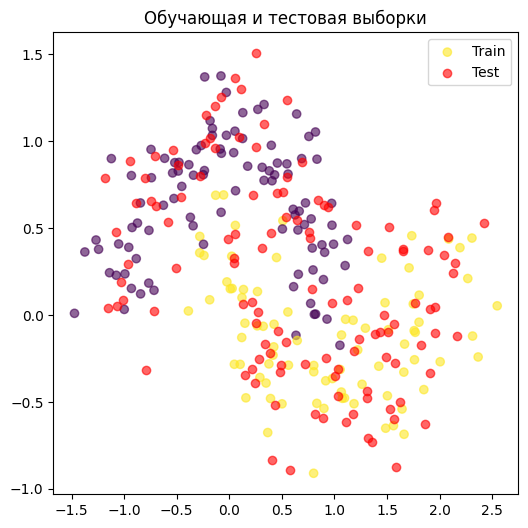


Обучение модели NaiveBayes (Gaussian)
Модель обучена на 180 образцах
Количество классов: 2
Количество признаков: 2

Предсказание и оценка качества

Точность (accuracy) модели: 0.9000

Первые 10 истинных меток: [1 1 1 1 1 0 1 0 1 1]
Первые 10 предсказаний:    [1 1 1 1 1 0 1 0 1 1]

Параметры обученной модели

Класс 0:
  Априорная вероятность P(0) = 0.5444
  Среднее: [-0.0101013   0.63487557]
  Дисперсия: [0.500045   0.12735291]

Класс 1:
  Априорная вероятность P(1) = 0.4556
  Среднее: [ 0.92983718 -0.10655803]
  Дисперсия: [0.59176561 0.12022374]

Границы решений


/tmp/ipykernel_2632/1032285961.py:155: UserWarning: You passed a edgecolor/edgecolors ('w') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',


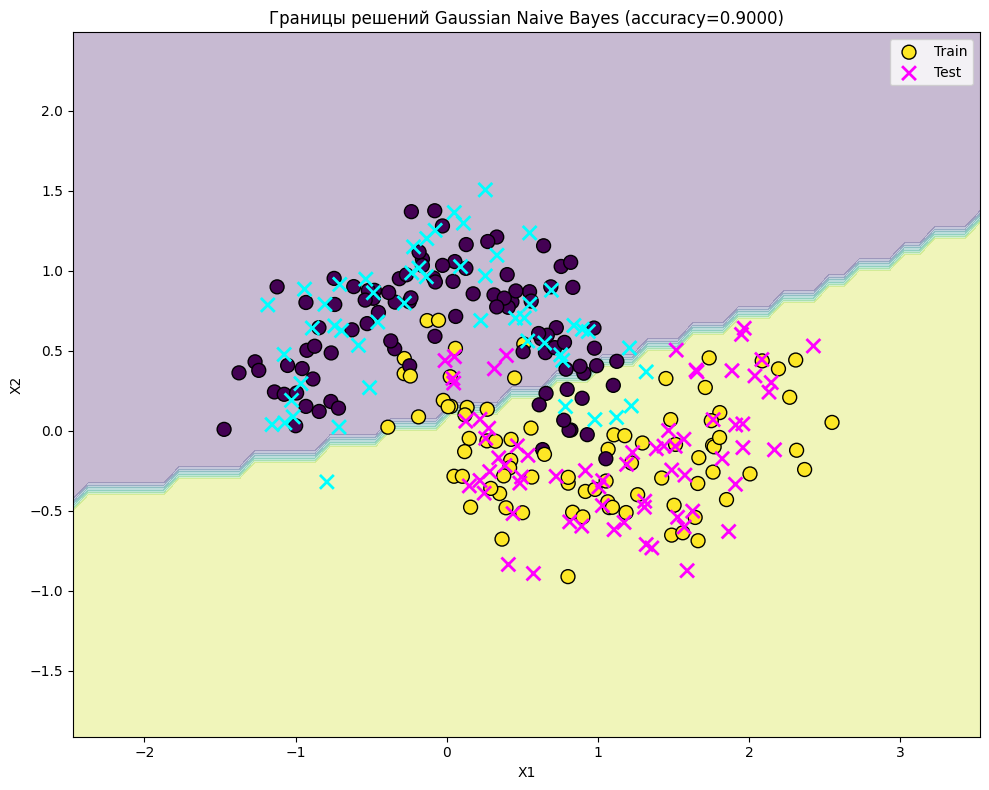


Тестирование predict() с новыми данными

Предсказания для новых точек:
Точка                          Предсказание   
---------------------------------------------
  [-1.47250233 -0.91160797] -> 1
  [0.5381309  0.29635004] -> 0
  [2.54876413 1.50430805] -> 0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

class NaiveBayes:
    def __init__(self, dataset, targets):
        self.dataset = np.array(dataset)
        self.targets = np.array(targets)
        self.n_features = self.dataset.shape[1]

        self.classes = np.unique(self.targets)

        self.class_params = {}

        self.fitted = False

    def fit(self):
        for c in self.classes:
            X_c = self.dataset[self.targets == c]

            mean = np.mean(X_c, axis=0)
            var = np.var(X_c, axis=0)

            var = np.where(var == 0, 1e-9, var)

            prior = len(X_c) / len(self.dataset)

            self.class_params[c] = {
                'mean': mean,
                'var': var,
                'prior': prior
            }

        self.fitted = True
        print(f"Модель обучена на {len(self.dataset)} образцах")
        print(f"Количество классов: {len(self.classes)}")
        print(f"Количество признаков: {self.n_features}")
        return self

    def _gaussian_prob(self, x, mean, var):

        z = np.sqrt(2 * np.pi * var)

        log_prob = -np.log(z) - ((x - mean) ** 2) / (2 * var)

        return log_prob

    def predict(self, list2d):
        if not self.fitted:
            raise ValueError("Модель еще не обучена. Вызовите fit() перед predict().")

        list2d = np.array(list2d)
        predictions = []

        for sample in list2d:
            log_probs = {}

            for c in self.classes:
                params = self.class_params[c]

                log_prior = np.log(params['prior'])

                log_likelihood = 0
                for i in range(self.n_features):
                    log_likelihood += self._gaussian_prob(
                        sample[i],
                        params['mean'][i],
                        params['var'][i]
                    )

                log_probs[c] = log_prior + log_likelihood

            predicted_class = max(log_probs, key=log_probs.get)
            predictions.append(predicted_class)

        return np.array(predictions)

print("=" * 60)
print("Создание данных (gaussian blobs)")
print("=" * 60)

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

print(f"Размер данных: {X.shape}")
print(f"Распределение классов: {np.bincount(y)}")

plt.figure(figsize=(7, 7))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k')
plt.title('Исходные данные (3 класса)')
plt.show()

print("\n" + "=" * 60)
print("Разбиение на обучающую и тестовую выборки")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} образцов")
print(f"Тестовая выборка: {X_test.shape[0]} образцов")

plt.figure(figsize=(6, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', alpha=0.6, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c='red', alpha=0.6, label='Test')
plt.legend()
plt.title('Обучающая и тестовая выборки')
plt.show()

print("\n" + "=" * 60)
print("Обучение модели NaiveBayes (Gaussian)")
print("=" * 60)

nb = NaiveBayes(X_train, y_train)
nb.fit()

print("\n" + "=" * 60)
print("Предсказание и оценка качества")
print("=" * 60)

y_pred = nb.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nТочность (accuracy) модели: {accuracy:.4f}")

print(f"\nПервые 10 истинных меток: {y_test[:10]}")
print(f"Первые 10 предсказаний:    {y_pred[:10]}")

print("\n" + "=" * 60)
print("Параметры обученной модели")
print("=" * 60)

for c in nb.classes:
    params = nb.class_params[c]
    print(f"\nКласс {c}:")
    print(f"  Априорная вероятность P({c}) = {params['prior']:.4f}")
    print(f"  Среднее: {params['mean']}")
    print(f"  Дисперсия: {params['var']}")

print("\n" + "=" * 60)
print("Границы решений")
print("=" * 60)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

Z = nb.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis',
            edgecolors='k', s=100, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',
            edgecolors='w', s=100, marker='x', linewidths=2, label='Test')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title(f'Границы решений Gaussian Naive Bayes (accuracy={accuracy:.4f})')
plt.legend()
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Тестирование predict() с новыми данными")
print("=" * 60)

test_points = np.array([
    [X[:, 0].min(), X[:, 1].min()],
    [(X[:, 0].min() + X[:, 0].max()) / 2, (X[:, 1].min() + X[:, 1].max()) / 2],
    [X[:, 0].max(), X[:, 1].max()]
])

predictions = nb.predict(test_points)

print(f"\nПредсказания для новых точек:")
print(f"{'Точка':<30} {'Предсказание':<15}")
print("-" * 45)
for i, (point, pred) in enumerate(zip(test_points, predictions)):
    print(f"  {point} -> {pred}")

Дано:
- класс DecisionTree.

Требуется:
- проверить работу алгоритма на тестовой выборке и посчитать достоверность (accuracy) модели;
- дописать метода print_tree(), который позволяет визуализировать дерево в текстовом виде.

Создание данных
Размер данных: (300, 2)
Распределение классов: [150 150]


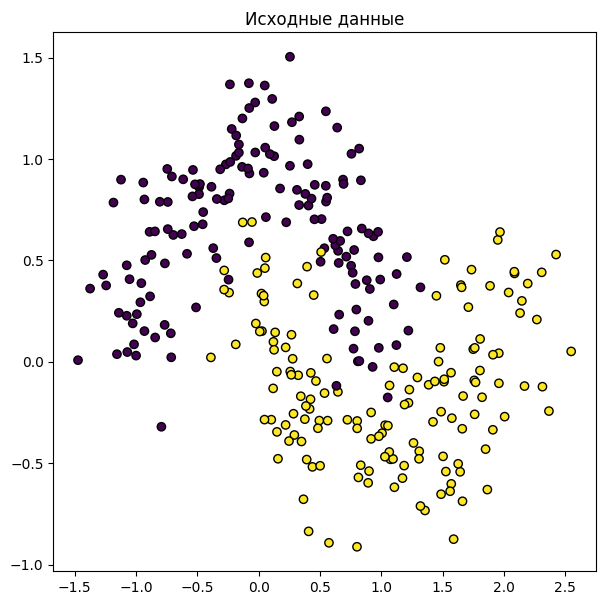


Разбиение на обучающую и тестовую выборки
Обучающая выборка: 180 образцов
Тестовая выборка: 120 образцов


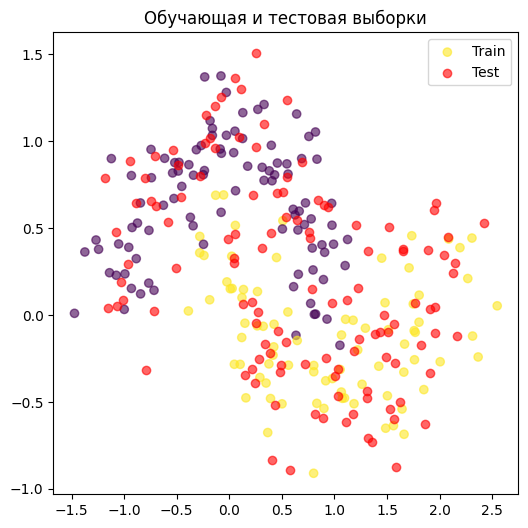


Обучение модели DecisionTree

Структура дерева:
---[X[1] <= 0.15]
|   ---[X[0] <= -0.72]
|   |   ---(leaf: 0)
|   |   ---[X[1] <= -0.18]
|   |   |   ---(leaf: 1)
|   |   |   ---[X[0] <= 1.05]
|   |   |   |   ---[X[0] <= 0.56]
|   |   |   |   |   ---(leaf: 1)
|   |   |   |   |   ---(leaf: 0)
|   |   |   |   ---(leaf: 1)
|   ---[X[0] <= 1.13]
|   |   ---[X[1] <= 0.69]
|   |   |   ---[X[0] <= -0.34]
|   |   |   |   ---(leaf: 0)
|   |   |   |   ---[X[0] <= 0.51]
|   |   |   |   |   ---(leaf: 1)
|   |   |   |   |   ---(leaf: 0)
|   |   |   ---(leaf: 0)
|   |   ---(leaf: 1)

Предсказание и оценка качества

Точность (accuracy) модели: 0.9500

Первые 10 истинных меток: [1 1 1 1 1 0 1 0 1 1]
Первые 10 предсказаний:    [1 1 1 1 1 0 1 0 1 1]

Границы решений


/tmp/ipykernel_2632/589189600.py:211: UserWarning: You passed a edgecolor/edgecolors ('w') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',


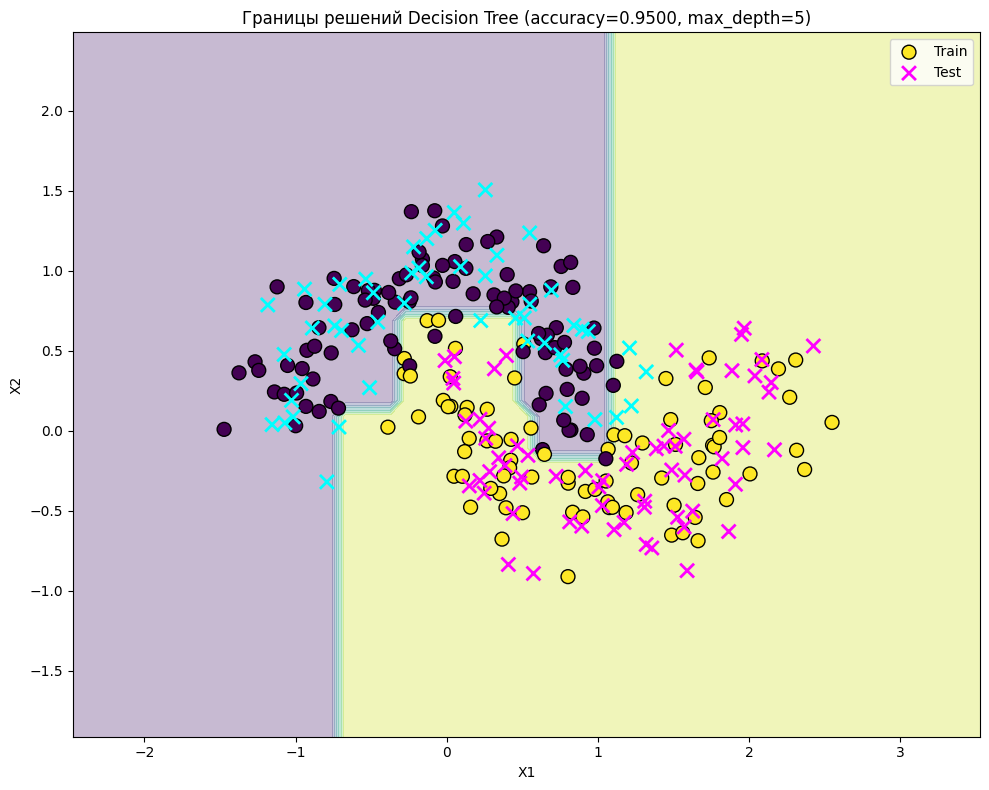


Сравнение с sklearn DecisionTreeClassifier

Точность нашей реализации: 0.9500
Точность sklearn DecisionTreeClassifier: 0.9667


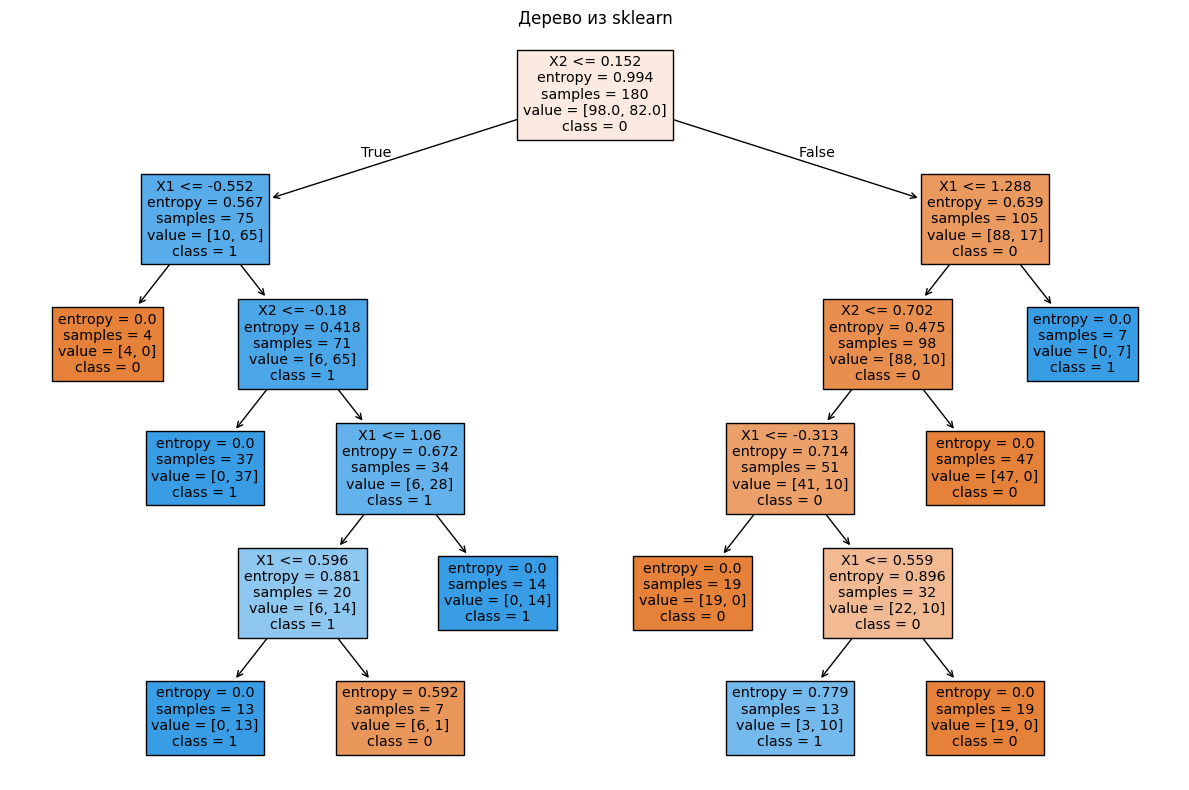


Влияние глубины дерева на точность
max_depth= 1: Train accuracy=0.8500, Test accuracy=0.7917
max_depth= 2: Train accuracy=0.9111, Test accuracy=0.8917
max_depth= 3: Train accuracy=0.9111, Test accuracy=0.8917
max_depth= 4: Train accuracy=0.9111, Test accuracy=0.8917
max_depth= 5: Train accuracy=0.9778, Test accuracy=0.9500
max_depth= 6: Train accuracy=0.9778, Test accuracy=0.9500
max_depth= 7: Train accuracy=0.9833, Test accuracy=0.9167
max_depth= 8: Train accuracy=0.9889, Test accuracy=0.9417
max_depth= 9: Train accuracy=0.9944, Test accuracy=0.9500
max_depth=10: Train accuracy=0.9944, Test accuracy=0.9167


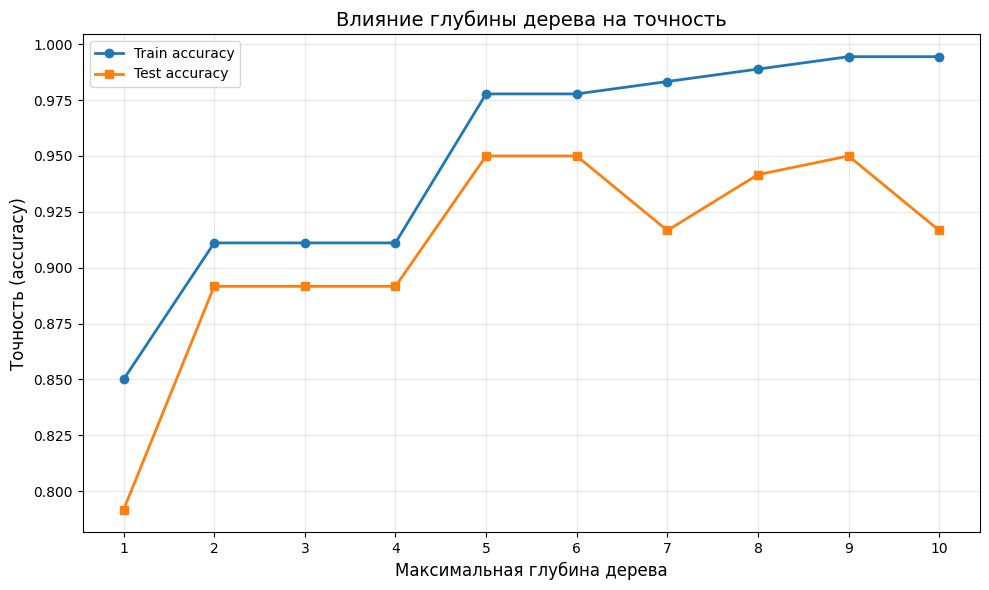

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import make_moons

class Node:

    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None

class DecisionTree:

    def __init__(self, max_depth=100, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _is_finished(self, depth):
        if (depth >= self.max_depth
            or self.n_class_labels == 1
            or self.n_samples < self.min_samples_split):
            return True
        return False

    def _build_tree(self, X, y, depth=0):
        self.n_samples, self.n_features = X.shape
        self.n_class_labels = len(np.unique(y))

        # stopping criteria
        if self._is_finished(depth):
            most_common_Label = np.argmax(np.bincount(y))
            return Node(value=most_common_Label)

        # get best split
        rnd_feats = np.random.choice(self.n_features, self.n_features, replace=False)
        best_feat, best_thresh = self._best_split(X, y, rnd_feats)

        # grow children recursively
        left_idx, right_idx = self._create_split(X[:, best_feat], best_thresh)
        left_child = self._build_tree(X[left_idx, :], y[left_idx], depth + 1)
        right_child = self._build_tree(X[right_idx, :], y[right_idx], depth + 1)
        return Node(best_feat, best_thresh, left_child, right_child)

    def fit(self, X, y):
        self.root = self._build_tree(X, y)

    def _entropy(self, y):
        proportions = np.bincount(y) / len(y)
        entropy = -np.sum([p * np.log2(p) for p in proportions if p > 0])
        return entropy

    def _create_split(self, X, thresh):
        left_idx = np.argwhere(X <= thresh).flatten()
        right_idx = np.argwhere(X > thresh).flatten()
        return left_idx, right_idx

    def _information_gain(self, X, y, thresh):
        parent_loss = self._entropy(y)
        left_idx, right_idx = self._create_split(X, thresh)
        n, n_left, n_right = len(y), len(left_idx), len(right_idx)

        if n_left == 0 or n_right == 0:
            return 0

        child_loss = (n_left / n) * self._entropy(y[left_idx]) + (n_right / n) * self._entropy(y[right_idx])
        return parent_loss - child_loss

    def _best_split(self, X, y, features):
        split = {'score':- 1, 'feat': None, 'thresh': None}

        for feat in features:
            X_feat = X[:, feat]
            thresholds = np.unique(X_feat)
            for thresh in thresholds:
                score = self._information_gain(X_feat, y, thresh)

                if score > split['score']:
                    split['score'] = score
                    split['feat'] = feat
                    split['thresh'] = thresh

        return split['feat'], split['thresh']

    def _traverse_tree(self, x, node):
        if node.is_leaf():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def predict(self, X):
        predictions = [self._traverse_tree(x, self.root) for x in X]
        return np.array(predictions)

    def print_tree(self, node, spacing="---", depth=0):
        """
        Метод визуализации дерева в текстовом виде
        Рекурсивно обходит дерево и выводит условия в каждом узле
        """
        if node is None:
            return

        indent = "|   " * depth

        if node.is_leaf():
            print(f"{indent}{spacing}(leaf: {node.value})")
            return

        # Вывод условия для внутреннего узла
        print(f"{indent}{spacing}[X[{node.feature}] <= {node.threshold:.2f}]")

        # Рекурсивный вызов для левого и правого дочерних узлов
        self.print_tree(node.left, spacing, depth + 1)
        self.print_tree(node.right, spacing, depth + 1)


# ==================== ПРИМЕР ИСПОЛЬЗОВАНИЯ ====================

print("=" * 60)
print("Создание данных")
print("=" * 60)

# Создание данных
X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

print(f"Размер данных: {X.shape}")
print(f"Распределение классов: {np.bincount(y)}")

# Визуализация
plt.figure(figsize=(7, 7))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k')
plt.title('Исходные данные')
plt.show()

# ==================== РАЗБИЕНИЕ НА TRAIN/TEST ====================

print("\n" + "=" * 60)
print("Разбиение на обучающую и тестовую выборки")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} образцов")
print(f"Тестовая выборка: {X_test.shape[0]} образцов")

# Визуализация
plt.figure(figsize=(6, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', alpha=0.6, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c='red', alpha=0.6, label='Test')
plt.legend()
plt.title('Обучающая и тестовая выборки')
plt.show()

# ==================== ОБУЧЕНИЕ МОДЕЛИ ====================

print("\n" + "=" * 60)
print("Обучение модели DecisionTree")
print("=" * 60)

# Инициализация и обучение модели
dt = DecisionTree(max_depth=5, min_samples_split=2)
dt.fit(X_train, y_train)

print("\nСтруктура дерева:")
dt.print_tree(dt.root)

# ==================== ПРЕДСКАЗАНИЕ И ACCURACY ====================

print("\n" + "=" * 60)
print("Предсказание и оценка качества")
print("=" * 60)

# Предсказание на тестовой выборке
y_pred = dt.predict(X_test)

# Вычисление accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nТочность (accuracy) модели: {accuracy:.4f}")

# Сравнение первых 10 предсказаний
print(f"\nПервые 10 истинных меток: {y_test[:10]}")
print(f"Первые 10 предсказаний:    {y_pred[:10]}")

# ==================== ВИЗУАЛИЗАЦИЯ ГРАНИЦ РЕШЕНИЙ ====================

print("\n" + "=" * 60)
print("Границы решений")
print("=" * 60)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

# Предсказание для каждой точки сетки
Z = dt.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis',
            edgecolors='k', s=100, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='cool',
            edgecolors='w', s=100, marker='x', linewidths=2, label='Test')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title(f'Границы решений Decision Tree (accuracy={accuracy:.4f}, max_depth=5)')
plt.legend()
plt.tight_layout()
plt.show()

# ==================== СРАВНЕНИЕ С SKLEARN ====================

print("\n" + "=" * 60)
print("Сравнение с sklearn DecisionTreeClassifier")
print("=" * 60)

from sklearn.tree import DecisionTreeClassifier

sklearn_dt = DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)
sklearn_dt.fit(X_train, y_train)
sklearn_accuracy = accuracy_score(y_test, sklearn_dt.predict(X_test))

print(f"\nТочность нашей реализации: {accuracy:.4f}")
print(f"Точность sklearn DecisionTreeClassifier: {sklearn_accuracy:.4f}")

# Визуализация дерева sklearn
plt.figure(figsize=(12, 8))
from sklearn.tree import plot_tree
plot_tree(sklearn_dt, feature_names=['X1', 'X2'], class_names=['0', '1'], filled=True)
plt.title('Дерево из sklearn')
plt.tight_layout()
plt.show()

# ==================== ВЛИЯНИЕ ГЛУБИНЫ ДЕРЕВА ====================

print("\n" + "=" * 60)
print("Влияние глубины дерева на точность")
print("=" * 60)

max_depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
train_accuracies = []
test_accuracies = []

for depth in max_depths:
    dt_test = DecisionTree(max_depth=depth, min_samples_split=2)
    dt_test.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, dt_test.predict(X_train))
    test_acc = accuracy_score(y_test, dt_test.predict(X_test))

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"max_depth={depth:2d}: Train accuracy={train_acc:.4f}, Test accuracy={test_acc:.4f}")

# График зависимости accuracy от глубины
plt.figure(figsize=(10, 6))
plt.plot(max_depths, train_accuracies, marker='o', label='Train accuracy', linewidth=2)
plt.plot(max_depths, test_accuracies, marker='s', label='Test accuracy', linewidth=2)
plt.xlabel('Максимальная глубина дерева', fontsize=12)
plt.ylabel('Точность (accuracy)', fontsize=12)
plt.title('Влияние глубины дерева на точность', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(max_depths)
plt.tight_layout()
plt.show()